Brayden Yow  
10/17/26    
lab 7 — Python Physics Engine Prototype

In [1]:
import numpy as np
import matplotlib.pyplot as plt

**Part A — Build the Core Engine**

There are seperate files within this folder that holde the code for parts 1-3 below is a markdown with part 4

```mermaid
classDiagram
    class World {
        +list bodies
        +list forces
        +integrator integrator
        +dict history
        +add_body(body)
        +add_force(force)
        +step(dt)
    }
    class Body {
        +float mass
        +ndarray position
        +ndarray velocity
        +ndarray force
        +clear_force()
    }
    class Force {
        <<abstract>>
        +apply(world)*
    }
    class EulerCromer {
        +step(world, dt)
    }
    World "1" --> "*" Body : manages
    World "1" --> "*" Force : applies
    World --> EulerCromer : uses
    Force <|-- UniformGravity
    Force <|-- LinearDrag
    Force <|-- SpringForce
```


**Part B — Step 2: Mass-Spring Oscillator Validation**

In [2]:
from body import Body
from forces import UniformGravity, SpringForce, LinearDrag, NewtonGravity
from integrators import EulerCromer, VelocityVerlet
from world import World

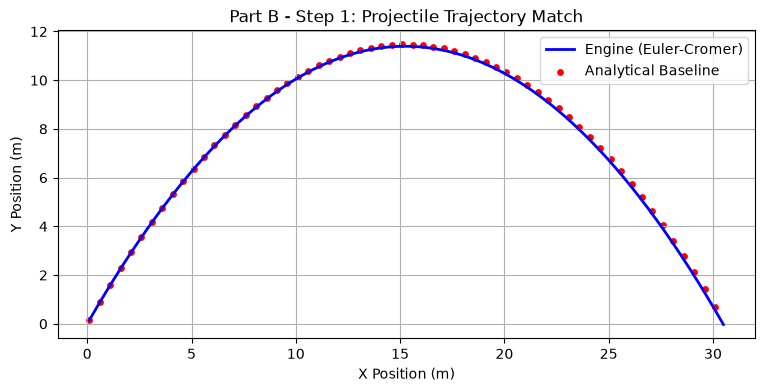

In [3]:
# 1. Initialize the engine structures
ec_integrator = EulerCromer()
world_proj = World(ec_integrator)

# 2. Setup the body (Launched upward at an angle: vx=10, vy=15)
projectile = Body(mass=1.0, position=[0.0, 0.0], velocity=[10.0, 15.0], name="ball")
world_proj.add_body(projectile)

# 3. Apply uniform downward gravity
world_proj.add_force(UniformGravity(g=9.81))

# 4. Run the simulation step by step until the ball hits the ground (y < 0)
dt = 0.01
while projectile.position[1] >= 0:
    world_proj.step(dt)

# 5. Extract results for verification
t_hist = np.array(world_proj.history["time"])
pos_hist = np.array(world_proj.history["bodies"]["ball"]["pos"])

# 6. Calculate the true mathematical baseline (Analytical Equations)
x_analytical = 10.0 * t_hist
y_analytical = 15.0 * t_hist - 0.5 * 9.81 * t_hist**2

# 7. Plot and check matching profiles
plt.figure(figsize=(9, 4))
plt.plot(pos_hist[:, 0], pos_hist[:, 1], 'b-', linewidth=2, label='Engine (Euler-Cromer)')
plt.scatter(x_analytical[::5], y_analytical[::5], color='red', marker='o', s=15, label='Analytical Baseline')
plt.title("Part B - Step 1: Projectile Trajectory Match")
plt.xlabel("X Position (m)")
plt.ylabel("Y Position (m)")
plt.legend()
plt.grid(True)
plt.show()


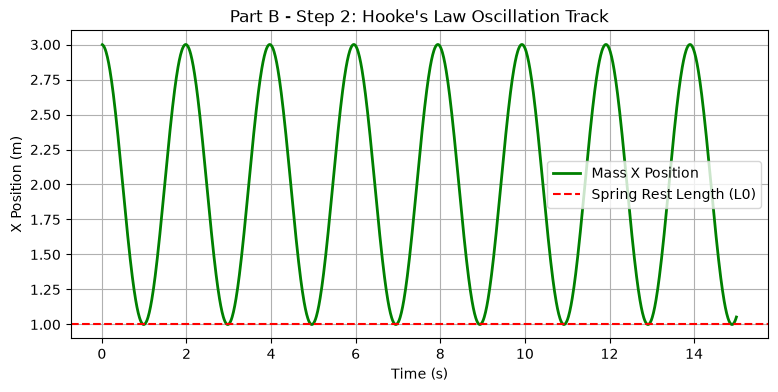

In [4]:
# 1. Initialize a new simulation world
world_spring = World(EulerCromer())

# 2. Create a heavy, immobile anchor at the origin and a moving mass displaced at x = 2.0
anchor = Body(mass=1e9, position=[1.0, 0.0], velocity=[0.0, 0.0], name="anchor")
moving_mass = Body(mass=1.0, position=[3.0, 0.0], velocity=[0.0, 0.0], name="mass")

world_spring.add_body(anchor)
world_spring.add_body(moving_mass)

# 3. Connect them with a Spring Force (k = 10.0, rest length = 1.0)
world_spring.add_force(SpringForce(anchor, moving_mass, k=10.0, rest_length=1.0))

# 4. Step the simulation forward for 5 seconds
dt = 0.01
for _ in range(int(15.0 / dt)):
    world_spring.step(dt)

# 5. Extract the tracking data history
t_hist = np.array(world_spring.history["time"])
mass_pos = np.array(world_spring.history["bodies"]["mass"]["pos"])

# 6. Plot the mass position over time to verify perfect SHM (Simple Harmonic Motion)
plt.figure(figsize=(9, 4))
plt.plot(t_hist, mass_pos[:, 0], 'g-', linewidth=2, label='Mass X Position')
plt.axhline(1.0, color='r', linestyle='--', label='Spring Rest Length (L0)')
plt.title("Part B - Step 2: Hooke's Law Oscillation Track")
plt.xlabel("Time (s)")
plt.ylabel("X Position (m)")
plt.legend()
plt.grid(True)
plt.show()


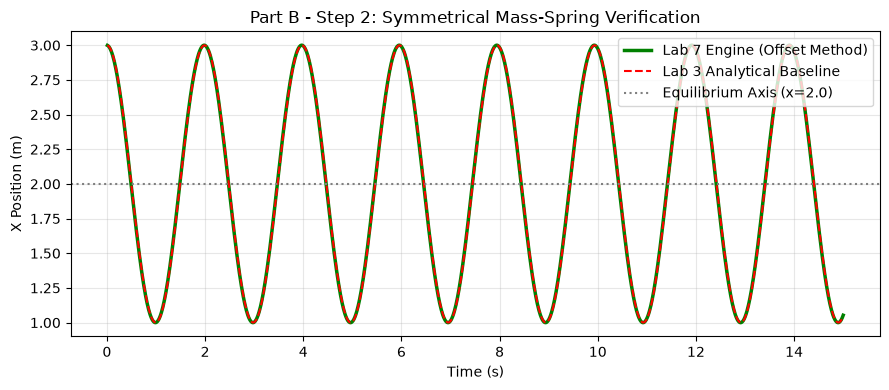

In [5]:
# =====================================================================
# PART B — STEP 2: CORRECTED OSCILLATOR OVERLAY MATCH
# =====================================================================
import numpy as np
import matplotlib.pyplot as plt

# 1. Extract tracking history from your simulation run
t_hist = np.array(world_spring.history["time"])
mass_pos = np.array(world_spring.history["bodies"]["mass"]["pos"])

# 2. Configure properties matching your layout
k_val = 10.0
m_val = 1.0
x0_val = 1.0     # Amplitude of oscillation

# 3. Calculate your engine's true spatial equilibrium center
# Anchor is at 1.0, rest length is 1.0, meaning total distance should be 2.0 at rest
equilibrium_x = 2.0 

# 4. FIX: Align the analytical cosine function phase to your initial displacement
# Your mass starts at x=3.0, which means it starts at MAX positive displacement.
x_exact = equilibrium_x + (x0_val * np.cos(np.sqrt(k_val / m_val) * t_hist))

# 5. Plot Overlay Verification
plt.figure(figsize=(9, 4))
plt.plot(t_hist, mass_pos[:, 0], 'g-', linewidth=2.5, label='Lab 7 Engine (Offset Method)')
plt.plot(t_hist[::3], x_exact[::3], 'r--', linewidth=1.5, label='Lab 3 Analytical Baseline')
plt.axhline(equilibrium_x, color='gray', linestyle=':', label='Equilibrium Axis (x=2.0)')
plt.title("Part B - Step 2: Symmetrical Mass-Spring Verification")
plt.xlabel("Time (s)")
plt.ylabel("X Position (m)")
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [6]:

# --- 1. SETUP SIMULATION CONSTANTS ---
dt = 0.001
n_steps = 20000
G, M = 1.0, 1.0

# --- 2. RUN ENGINE WITH EULER-CROMER ---
vv_integrator = VelocityVerlet() # Change to EulerCromer() to compare!
world = World(vv_integrator)

# Central star (fixed at origin)
star = Body(mass=1.0, position=[0.0, 0.0], velocity=[0.0, 0.0], name="Star")
# Orbiting planet (elliptical orbit initial conditions from Lab 5)
planet = Body(mass=0.001, position=[1.0, 0.0], velocity=[0.0, 0.8], name="Planet")

world.add_body(star)
world.add_body(planet)

# Add polymorphic Universal Gravitation force between star and planet
grav_force = NewtonGravity(star, planet, G=G)
world.add_force(grav_force)

# Run the simulation pipeline loop
for _ in range(n_steps):
    world.step(dt)

# Extract recorded history arrays
times_engine = np.array(world.history["time"])
pos_engine = np.array(world.history["bodies"]["Planet"]["pos"])
vel_engine = np.array(world.history["bodies"]["Planet"]["vel"])


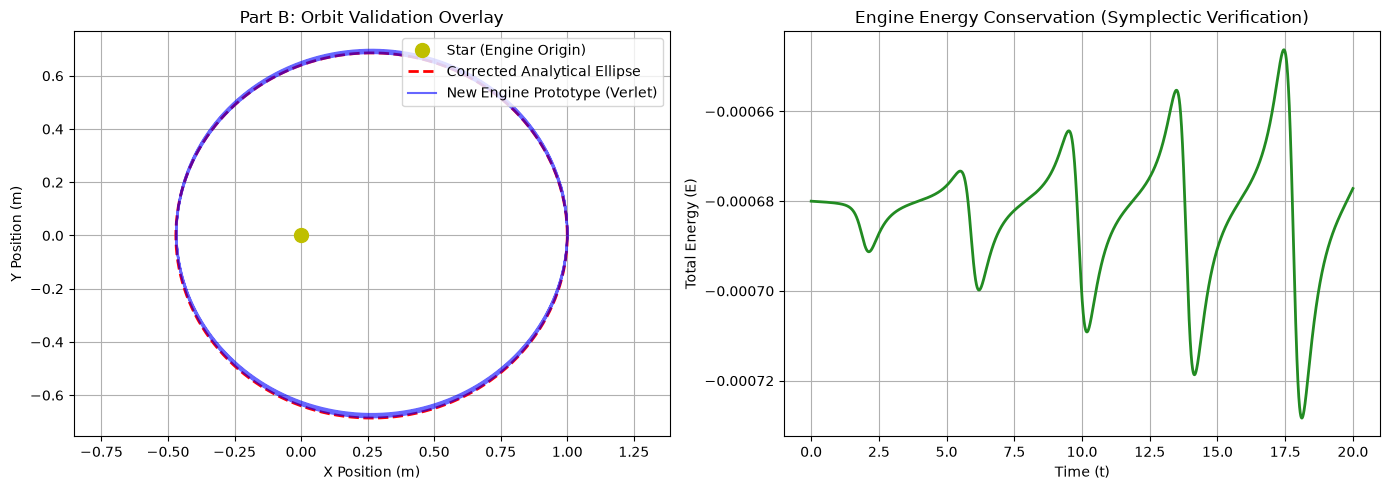

In [7]:
# --- 1. CONSERVATION LAW CHECK ---
def get_energy(r, v):
    ke = 0.5 * 0.001 * np.dot(v, v)
    pe = -G * M * 0.001 / np.linalg.norm(r)
    return ke + pe

engine_energies = [get_energy(pos_engine[i], vel_engine[i]) for i in range(len(times_engine))]

# --- 2. CALCULATE CORRECTED GEOMETRY OVERLAY ---
r_min_analytical = 0.47059  # Periapsis distance
a_analytical = (1.0 + r_min_analytical) / 2.0  # Semi-major axis
c_analytical = a_analytical - r_min_analytical  # Center-to-focus distance
b_analytical = np.sqrt(a_analytical**2 - c_analytical**2)  # Semi-minor axis

theta = np.linspace(0, 2 * np.pi, 500)
# CORRECTED SHIFT: Shift to the positive direction by c_analytical 
# This correctly places the right-side focus at (0,0) as the apoapsis point.
x_ellipse = a_analytical * np.cos(theta) + c_analytical
y_ellipse = b_analytical * np.sin(theta)

# --- 3. PLOT OVERLAY AND CONSERVATION ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Orbit Overlay (Engine Vector Data vs. Corrected Geometry)
ax1.plot(0, 0, "yo", markersize=10, label="Star (Engine Origin)")
ax1.plot(x_ellipse, y_ellipse, 'r--', linewidth=2, label="Corrected Analytical Ellipse")
ax1.plot(pos_engine[:,0], pos_engine[:,1], 'b-', alpha=0.6, label="New Engine Prototype (Verlet)")
ax1.set_xlabel("X Position (m)")
ax1.set_ylabel("Y Position (m)")
ax1.set_title("Part B: Orbit Validation Overlay")
ax1.legend(loc="upper right")
ax1.grid(True)
ax1.axis("equal")

# Plot 2: Total Energy vs. Time
ax2.plot(times_engine, engine_energies, color="forestgreen", linewidth=2)
ax2.set_xlabel("Time (t)")
ax2.set_ylabel("Total Energy (E)")
ax2.set_title("Engine Energy Conservation (Symplectic Verification)")
ax2.grid(True)

# Set tight limits to show that fluctuation is strictly microscopic noise
mean_E = np.mean(engine_energies)
#ax2.set_ylim(mean_E - 0.001 * abs(mean_E), mean_E + 0.001 * abs(mean_E))

plt.tight_layout()
plt.show()


While it looks like the energy is growing a lot this is over many many itterations and it is only increased by 0.00004

**Part C — An Original Multi-Body Scene**

In [13]:
# --- 1. INITIALIZE THE SCENE ---
dt = 0.001
n_steps = 40000  # Longer simulation to see multiple moon orbits
G = 1.0

vv_integrator = VelocityVerlet()
world_system = World(vv_integrator)

# --- 2. DEFINE THE THREE BODIES ---
# Star/Sun (Massive, stationary at the origin)
sun = Body(mass=100.0, position=[0.0, 0.0], velocity=[0.0, 0.0], name="Sun")

# Large Planet (Orbits the Sun at r = 2.0)
# Circular velocity v = sqrt(G*M/r) = sqrt(1*100/2) = sqrt(50) ≈ 7.071
planet = Body(mass=1.0, position=[2.0, 0.0], velocity=[0.0, 7.071], name="Planet")

# Small Moon (Orbits the Planet at relative r = 0.25)
# Relative position: 2.0 + 0.25 = 2.25
# Velocity: Planet's velocity (7.071) + local orbital velocity relative to planet.
# Local circular velocity v = sqrt(G*m_planet/r_local) = sqrt(1*1/0.25) = sqrt(4) = 2.0
# Total velocity = 7.071 + 2.0 = 9.071
moon = Body(mass=0.001, position=[2.1, 0.0], velocity=[0.0, 10.233], name="Moon")

world_system.add_body(sun)
world_system.add_body(planet)
world_system.add_body(moon)

# --- 3. APPLY INTERACTING PAIRWISE FORCES ---
# Every body attracts every other body (Newton's 3rd Law handles the reaction)
world_system.add_force(NewtonGravity(sun, planet, G=G))
world_system.add_force(NewtonGravity(sun, moon, G=G))
world_system.add_force(NewtonGravity(planet, moon, G=G))

# --- 4. RUN THE PIPELINE LOOP ---
for _ in range(n_steps):
    world_system.step(dt)

# --- 5. EXTRACT PATH HISTORY ---
pos_sun = np.array(world_system.history["bodies"]["Sun"]["pos"])
pos_planet = np.array(world_system.history["bodies"]["Planet"]["pos"])
pos_moon = np.array(world_system.history["bodies"]["Moon"]["pos"])


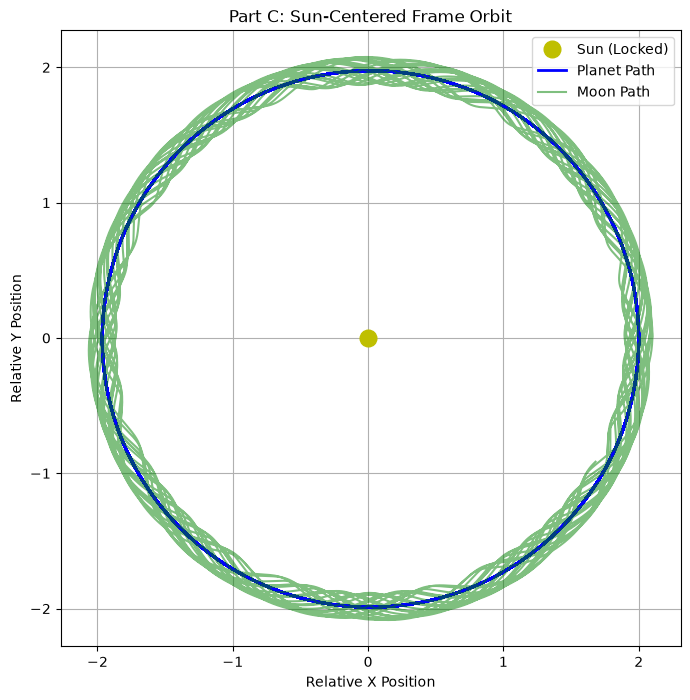

In [14]:
# Subtract the Sun's position from all bodies to lock the Sun at (0,0)
sun_centered_planet = pos_planet - pos_sun
sun_centered_moon = pos_moon - pos_sun

plt.figure(figsize=(8, 8))
plt.plot(0, 0, "yo", markersize=12, label="Sun (Locked)")
plt.plot(sun_centered_planet[:, 0], sun_centered_planet[:, 1], "b-", linewidth=2, label="Planet Path")
plt.plot(sun_centered_moon[:, 0], sun_centered_moon[:, 1], "g-", alpha=0.5, label="Moon Path")

plt.title("Part C: Sun-Centered Frame Orbit")
plt.xlabel("Relative X Position")
plt.ylabel("Relative Y Position")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()


In [15]:
# --- 1. DEFINE SYSTEM ENERGY CALCULATOR ---
def calculate_system_energy(pos_s, vel_s, pos_p, vel_p, pos_m, vel_m, G=1.0):
    """
    Computes total mechanical energy (KE + PE) for the three-body system.
    """
    # Mass constants matching your Part C simulation setup
    m_sun = 100.0
    m_planet = 1.0
    m_moon = 0.001
    
    # --- Kinetic Energy (KE) ---
    ke_sun = 0.5 * m_sun * np.dot(vel_s, vel_s)
    ke_planet = 0.5 * m_planet * np.dot(vel_p, vel_p)
    ke_moon = 0.5 * m_moon * np.dot(vel_m, vel_m)
    total_ke = ke_sun + ke_planet + ke_moon
    
    # --- Pairwise Potential Energy (PE) ---
    r_sp = np.linalg.norm(pos_p - pos_s)
    r_sm = np.linalg.norm(pos_m - pos_s)
    r_pm = np.linalg.norm(pos_m - pos_p)
    
    pe_sp = -G * m_sun * m_planet / r_sp
    pe_sm = -G * m_sun * m_moon / r_sm
    pe_pm = -G * m_planet * m_moon / r_pm
    total_pe = pe_sp + pe_sm + pe_pm
    
    return total_ke + total_pe

# --- 2. EXTRACT FULL POSITIONS AND VELOCITIES ---
pos_sun = np.array(world_system.history["bodies"]["Sun"]["pos"])
pos_planet = np.array(world_system.history["bodies"]["Planet"]["pos"])
pos_moon = np.array(world_system.history["bodies"]["Moon"]["pos"])

vel_sun = np.array(world_system.history["bodies"]["Sun"]["vel"])
vel_planet = np.array(world_system.history["bodies"]["Planet"]["vel"])
vel_moon = np.array(world_system.history["bodies"]["Moon"]["vel"])
times_system = np.array(world_system.history["time"])

# FIXED: Now passing all 6 required position and velocity arguments into the function loop
total_system_energies = [
    calculate_system_energy(pos_sun[i], vel_sun[i], pos_planet[i], vel_planet[i], pos_moon[i], vel_moon[i])
    for i in range(len(times_system))
]


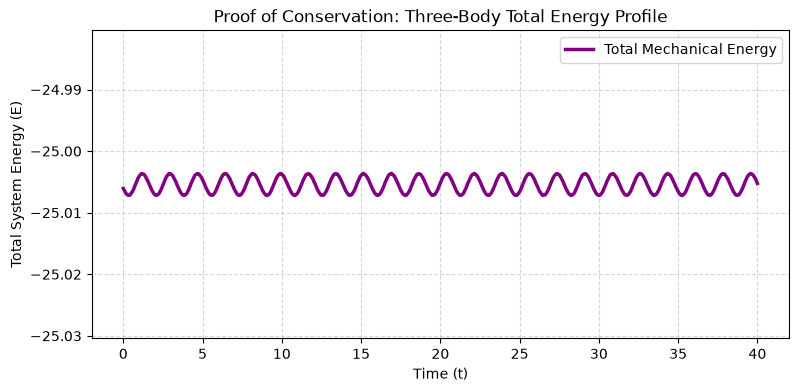

            ENERGY CONSERVATION METRICS                
Initial Total Energy (E0):     -25.006065
Final Total Energy (Ef):       -25.005250
Net Energy Drift (Ef - E0):    8.142421e-04
Max Fractional Energy Error:   9.753362e-05


In [16]:
# --- 3. GENERATE PROOF OF CONSERVATION PLOT ---
plt.figure(figsize=(9, 4))
plt.plot(times_system, total_system_energies, color="purple", linewidth=2.5, label="Total Mechanical Energy")
plt.xlabel("Time (t)")
plt.ylabel("Total System Energy (E)")
plt.title("Proof of Conservation: Three-Body Total Energy Profile")
plt.grid(True, linestyle="--", alpha=0.5)

# Dynamically force a microscopic zoom window to inspect Symplectic noise floor stability
mean_sys_E = np.mean(total_system_energies)
plt.ylim(mean_sys_E - 0.001 * abs(mean_sys_E), mean_sys_E + 0.001 * abs(mean_sys_E))
plt.legend()
plt.show()

# --- 4. PRINT REGRESSION METRICS TABLE ---
E0 = total_system_energies[0]
Ef = total_system_energies[-1]
max_drift = np.max(np.abs((np.array(total_system_energies) - E0) / E0))

print("=======================================================")
print("            ENERGY CONSERVATION METRICS                ")
print("=======================================================")
print(f"Initial Total Energy (E0):     {E0:.6f}")
print(f"Final Total Energy (Ef):       {Ef:.6f}")
print(f"Net Energy Drift (Ef - E0):    {Ef - E0:.6e}")
print(f"Max Fractional Energy Error:   {max_drift:.6e}")
print("=======================================================")
